# MECHA in metafspm, 11: barriers, the formalism

How MECHA's component writes the root's barriers: which **parameters** declare them (per plant, in the scenario),
which **rate step** turns them into the edges' conductances, which **intermediate states** it writes on the
DataStructure so that each layer can be read, and how the Casparian bands' reflection coefficient enters the water's
**graph system**, its flow law and its Jacobian. The user's view of the same barriers is user tutorial 9; the
equations are in `doc/equations.rst` (Conductances: walls, membranes; The water balance), the comparison with the
legacy MECHA (PR #67) in `doc/legacy.rst` (d13–d21) and `test/comparison/test_suberin_lamella.py`,
`test_casparian_reflection.py`, `test_membrane_permeability.py`. **Run time:** about 30 seconds.

> **Developer tutorial 11** of thirteen:
> | | notebook | what it covers |
> |---|---|---|
> | 0 | `00_overview.ipynb` | the package's modules, the original MECHA and its reactions branch, how the port is validated, the docs |
> | 1 | `01_granap_mecha.ipynb` | GRANAP's anatomies and MECHA's hydraulics coupled in a plant model; MECHA's inputs by role; scenarios; the barriers |
> | 2 | `02_soil_gradient.ipynb` | the plant problem with a soil drier on one side of a root section; a root partly out of contact, by position or by cells |
> | 3 | `03_needle_solutes.ipynb` | a pine needle of three sections, its transpiration, MechaSolutes over a day |
> | 4 | `04_full_plant.ipynb` | a whole seedling in its soil, run to the fixed point |
> | 5 | `05_extend_the_component.ipynb` | add a variable and a process to the component, run and test it |
> | 6 | `06_solute_storage_and_decay.ipynb` | the solutes' storage fractions, their first-order loss and the liquid boundary |
> | 7 | `07_section_options.ipynb` | the section's hydraulic options: the barrier codes 0-11, φ-thickenings, sclerenchyma, the exodermis' own values, aquaporins, plasmodesmata rules, walls and air spaces, xylem pieces, tracheids, measured axial conductances |
> | 8 | `08_standard_problem.ipynb` | the standard problem's boundaries (soil sides, xylem and phloem pressures or flows, the elongation zone), the osmotic scenarios and the Casparian bands' σ, the flows by layer |
> | 9 | `09_solute_options.ipynb` | the solutes' pathways, schemes and time steps, held concentrations, their fluxes and steady states, the bands' σ, the coupled water and sugar |
> | 10 | `10_root_system_conductance.ipynb` | a root system's conductance (MARSHAL's Krs, SUF) upscaled from the anatomical network, and a two-parameter calibration on it |
> | 11 | `11_barriers_formalism.ipynb` | the barriers from the declarations: the walls' layers in parallel, the membranes' resistances in series, the bands' σ in the flow law and its Jacobian, the membranes' permeability from their structure |
> | 12 | `12_from_the_legacy.ipynb` | for developers of the original MECHA: one section run with the legacy `Mecha` and with the components, each XML input mapped to its parameter, the results compared |
>
> New to MECHA? Start with the user tutorials (`../user/01_first_run.ipynb`): they solve a root section and explain
> its results without the framework's details.

In [1]:
import inspect

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.metafspm import CompositeModel, Planting, planting, Scene

from openalea.granap.metafspm.architectures import RootAxis
from openalea.granap.metafspm.component import GranapAnatomy, junction_rules
from openalea.mecha.component import MechaHydraulics, junction_wall_mean
from openalea.mecha.conductance import air_space_lining_walls, suberin_lamella
from openalea.mecha.geometry import MEMBRANE, WALL, WALL_PATH
from openalea.mecha.osmotic import MechaOsmoticPresets, casparian_bands
from openalea.mecha.stand_ins import Development


class RootWithPresets(CompositeModel):                 # tutorial 8's plant model: the osmotic presets before MECHA
    initiators = (RootAxis, GranapAnatomy)
    from_scale, nodes, wiring = "SubOrgan", "Compartment", junction_rules

    parts = {"anatomy": GranapAnatomy, "development": Development, "osmotic": MechaOsmoticPresets,
             "hydraulics": MechaHydraulics}
    schedule = ("development", "anatomy", "osmotic", "hydraulics")


def section(barrier, **parameters):
    """One root section at *barrier*, MECHA's and the presets' *parameters* in its scenario, solved once; returns
    (its DataStructure, its MechaHydraulics, MECHA's network of the section: the edges' ends and the cells' groups)."""
    scene = Scene(planting([Planting()], RootWithPresets, dict(parameters, mature_barrier=float(barrier))))
    scene.run()
    population = scene.populations[0]
    mecha = population.instance.hydraulics
    return population.data_structure, mecha, mecha.network()


def membrane_faces(net):
    """The membrane edges of the section, each one's cell, and the cell group (MECHA's cgroup: 1 exodermis, 3
    endodermis, 4 cortex, > 4 the stele) of its own cell and of the other cell of its wall (-1: a border wall)."""
    membranes = np.flatnonzero(net.in_section & (net.path == MEMBRANE))
    wall_is_a = net.compartment_type[net.a[membranes]] == WALL
    wall = np.where(wall_is_a, net.a[membranes], net.b[membranes])
    cell = np.where(wall_is_a, net.b[membranes], net.a[membranes])
    cells = net.wall_cells[wall]
    other = np.where((cells >= 0).all(axis=1), np.where(cells[:, 0] == cell, cells[:, 1], cells[:, 0]), -1)
    return membranes, cell, net.cgroup[cell], np.where(other >= 0, net.cgroup[np.maximum(other, 0)], -1)

## 1. The declarations

A barrier is a set of **parameters** of MechaHydraulics (one value per plant, given in its scenario), read by its
rate step `_conductance`, which writes every edge's `conductance`. Since PR #67 the walls and the suberized membranes
are made of layers; the step also writes each layer as an **intermediate state** of the edges, declared with the
others, so that a developer (or a test) can read what the conductance is made of:

In [2]:
declarations = MechaHydraulics.declarations().set_index("name")
barrier_parameters = ["kw", "kw_casparian", "kw_suberin_out", "kw_suberin_in", "kw_suberin_radial",
                      "kw_casparian_exodermis", "kw_suberin_exodermis", "kw_septa", "suberin_model",
                      "primary_wall_thickness", "secondary_wall_thickness", "tertiary_wall_thickness",
                      "lamella_wall_half"]
layer_states = ["wall_layer_conductivity", "wall_thickness_total", "membrane_wall_half_resistance",
                "membrane_lamella_resistance", "membrane_tertiary_resistance", "membrane_resistance"]
with pd.option_context("display.max_colwidth", 140):
    display(declarations.loc[barrier_parameters + layer_states, ["role", "unit", "default", "description"]])

,role,unit,default,description
name,,,,
kw,parameter,cm2 hPa-1 d-1,0.00024,cell wall hydraulic conductivity
kw_casparian,parameter,cm2 hPa-1 d-1,0.0,wall conductivity across a Casparian strip
kw_suberin_out,parameter,cm2 hPa-1 d-1,0.0,"conductivity of suberized walls, outer face"
kw_suberin_in,parameter,cm2 hPa-1 d-1,0.0,"conductivity of suberized walls, inner face"
kw_suberin_radial,parameter,cm2 hPa-1 d-1,NaN,"conductivity of the endodermis' suberin lamella on its radial faces, toward another endodermal cell (suberin_model 1; PR #67's Sub; NaN:..."
kw_casparian_exodermis,parameter,cm2 hPa-1 d-1,NaN,wall conductivity across the exodermis' Casparian strip (PR #67's Casp_exo; NaN: kw_casparian)
kw_suberin_exodermis,parameter,cm2 hPa-1 d-1,NaN,"conductivity of the exodermis' suberin, both faces (PR #67's Sub_exo; NaN: kw_suberin_out toward the epidermis, kw_suberin_in toward the..."
kw_septa,parameter,cm2 hPa-1 d-1,0.00012,"a desiccated wall's conductivity: the septa between two air spaces (intercellular cells), the air-side half of a wall lining one (with b..."
suberin_model,parameter,,0.0,the suberin of the endodermis and the exodermis: 0 a conductivity of the wall half in series with their membranes (MECHA's); 1 a lamella...


`_conductance` is one rate step (`include_inactive=True`: the conductances of every section, each step); its
docstring and the tuple it returns name what it writes:

In [3]:
print(inspect.getdoc(MechaHydraulics._conductance))

Every edge's conductance, and the boundary conductances of the nodes (soil, axial), from MECHA's geometry,
the segments' barriers and heights (their lengths), and the plants' parameters; the standard problem's
boundary potentials (the axial boundary only where its potential is given: not at barrier 0 by default).
Its intermediate states: the layers the walls' and the membranes' conductances are made of (the walls' in
parallel, the membranes' path in series).
Computed again only when one of these, the parameters, the settings or the structure changed (memo=True).


The rules themselves are functions of `conductance.py` (`edge_conductances`, `suberin_lamella`,
`air_space_lining_walls`), on MECHA's `Network` (the section's arrays: the edges' ends `a`, `b`, their `path`, the
cells' `cgroup`, each wall's two cells `wall_cells`). A suberized endodermis (barrier 3) with the lamella model and
distinct values for each face, so that every layer shows:

In [4]:
LAMELLA = dict(suberin_model=1., secondary_wall_thickness=0.5, tertiary_wall_thickness=1.0, kw_casparian=1.0E-9,
               kw_suberin_in=3.0E-9, kw_suberin_out=5.0E-9, kw_suberin_radial=7.0E-9)
data, mecha, net = section(3, **LAMELLA)
edge = lambda name: np.asarray(data.get(name), dtype=float)
kw = float(mecha.kw)
print(f"kr {float(data.get('kr')[0]):.4g} cm hPa-1 d-1")

kr 5.3e-05 cm hPa-1 d-1


## 2. The walls: layers in parallel

Along a wall (its two **wall edges**, from the wall's node to its junctions) the water flows through every layer side
by side: the middle layer (the primary walls, `primary_wall_thickness` p, the conductivity the barrier code gives the
wall, k_mid) and, on each suberized side, the secondary layer (thickness s, the lamella's conductivity k_lam). Their
conductivity in parallel, weighted by thickness, is the state `wall_layer_conductivity`:

$$k_\text{wall} = \frac{p\,k_\text{mid} + s_1 k_{\text{lam},1} + s_2 k_{\text{lam},2}}{p + s_1 + s_2},$$

and the wall's conductance is k_wall × its cross section (thickness p + s₁ + s₂ × the height) / its length. The
tertiary layers (`tertiary_wall_thickness`) do not conduct along the wall: they add to `wall_thickness_total` only.

The walls between an endodermal and a cortical cell: one suberized side (the endodermis' outer face, `kw_suberin_out`):

In [5]:
walls = np.flatnonzero(net.in_section & net.junction_edge)
wall_node = np.where(net.compartment_type[net.a[walls]] == WALL, net.a[walls], net.b[walls])
cells = net.wall_cells[wall_node]
groups = np.sort(np.where(cells >= 0, net.cgroup[np.maximum(cells, 0)], -1), axis=1)
endodermis_cortex = walls[(groups[:, 0] == 3) & (groups[:, 1] == 4)]
total = edge("wall_thickness_total")[endodermis_cortex]
secondary = LAMELLA["secondary_wall_thickness"]
primary = total - secondary                                       # one secondary layer, no tertiary on that face
expected = (primary * kw + secondary * LAMELLA["kw_suberin_out"]) / total
print(f"{endodermis_cortex.size} wall edges, total thickness {np.unique(total)} µm; "
      f"wall_layer_conductivity / kw: {np.unique(edge('wall_layer_conductivity')[endodermis_cortex] / kw)}; "
      f"largest relative difference from the formula: "
      f"{np.abs(edge('wall_layer_conductivity')[endodermis_cortex] / expected - 1).max():.1e}")

122 wall edges, total thickness [3.] µm; wall_layer_conductivity / kw: [0.83333681]; largest relative difference from the formula: 0.0e+00


**Walls lining an air space.** A wall with one root air space among its two cells is half hydrated (its own
conductivity) and half desiccated (`kw_septa`), in parallel: its conductivity is their mean (`air_space_lining_walls`,
at barrier > 0; MechaHydraulics checks `kw_septa` < `kw` before the conductances: `_check_desiccated_walls`):

In [6]:
lining = air_space_lining_walls(net, mecha.parameter_table(mecha.PARAMETERS, "edge"), np.full(net.path.size, 3.))
print(f"{lining.sum()} wall edges line an air space; their conductivity {np.unique(edge('wall_layer_conductivity')[lining])}"
      f" = (kw + kw_septa) / 2 = {(kw + float(mecha.kw_septa)) / 2}")

2392 wall edges line an air space; their conductivity [0.00018] = (kw + kw_septa) / 2 = 0.00018


The node input `wall_conductivity_factor` (a wall's own factor, user tutorial 10) multiplies the wall edges'
conductance after these rules; it is not part of `wall_layer_conductivity`.

## 3. The membranes: resistances in series

Water entering a cell crosses, in series, its half of the wall's middle layer, the lamella of the cell's face (with
`suberin_model` 1, on a suberized face), the endodermis' tertiary layer behind it (on the faces toward the stele and
toward the endodermis: a U shape) and the membrane itself. Each is a resistance (hPa d cm⁻¹), an intermediate state of
the membrane edges:

| state | resistance |
|---|---|
| `membrane_wall_half_resistance` | (p / 2) / k_half: `kw` on a suberized face (between two endodermal cells too), a face without a lamella its own value |
| `membrane_lamella_resistance` | s / k_lam: `kw_suberin_out`, `_in` or `_radial` by the face |
| `membrane_tertiary_resistance` | τ / kw |
| `membrane_resistance` | 1 / (kmb + kaqp × the tissue's factors × the cell's `aquaporin_factor`) |

and the membrane's conductance is its surface (the edge's length × (the height + the distance to the cell's centre),
the legacy's) over their sum. The suberin is on the **cell owning the membrane** (the original MECHA's rule, PR #67's
`suberin_lamella`): a cortical cell's membrane on the same wall has no lamella.

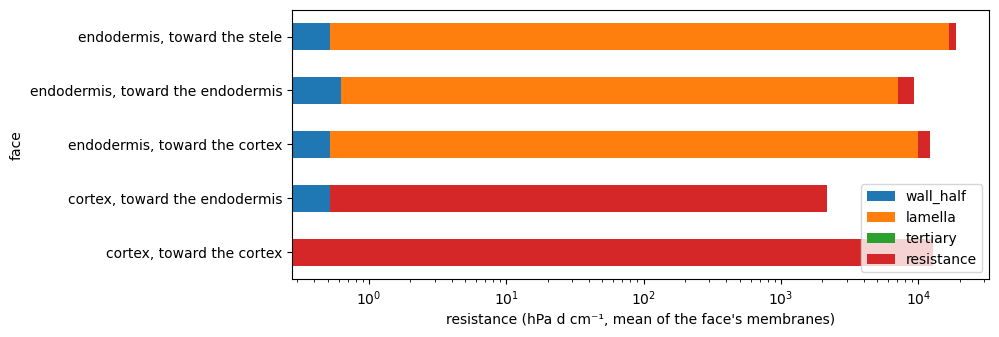

,wall_half,lamella,tertiary,resistance
face,,,,
"cortex, toward the cortex",0.274406,0.000000,0.000000,12823.202097
"cortex, toward the endodermis",0.520833,0.000000,0.000000,2173.913043
"endodermis, toward the cortex",0.520833,10000.000000,0.000000,2173.913043
"endodermis, toward the endodermis",0.625000,7142.857143,0.416667,2173.913043
"endodermis, toward the stele",0.520833,16666.666667,0.416667,2173.913043


In [7]:
membranes, cell, own, toward = membrane_faces(net)
face = np.select([(own == 3) & (toward == 4), (own == 3) & (toward > 4), (own == 3) & (toward == 3),
                  (own == 4) & (toward == 3), (own == 4) & (toward == 4)],
                 ["endodermis, toward the cortex", "endodermis, toward the stele", "endodermis, toward the endodermis",
                  "cortex, toward the endodermis", "cortex, toward the cortex"], "")
resistances = pd.DataFrame({name.removeprefix("membrane_").removesuffix("_resistance"): edge(name)[membranes]
                            for name in layer_states[2:]})
resistances["face"] = face
table = resistances[resistances["face"] != ""].groupby("face").mean()
table.plot.barh(stacked=True, logx=True, figsize=(9, 3.5), xlabel="resistance (hPa d cm⁻¹, mean of the face's membranes)")
plt.show()
table

- toward the cortex and the stele, the lamella (0.5 µm at 5 × 10⁻⁹ and 3 × 10⁻⁹) dominates by far;
- between two endodermal cells, the radial lamella (`kw_suberin_radial`) dominates too: the wall half is at `kw`
  there as on the other suberized faces, not at the Casparian band's value (the legacy's, `doc/legacy.rst` d19);
- the tertiary layer (1 µm at `kw`) is negligible; the cortex's membranes have neither lamella nor tertiary layer.

The conductance is the surface over the sum, to round-off:

In [8]:
series = sum(edge(name)[membranes] for name in layer_states[2:])
height = float(np.asarray(data.get("length"))[0]) * 1.0E6                   # µm
surface = 1.0E-8 * (height + net.edge_dist[membranes]) * net.edge_length[membranes]
conducting = edge("conductance")[membranes] > 1.0E-16                       # not the air spaces' membranes, cut
print(f"largest relative difference: {np.abs(edge('conductance')[membranes][conducting] / (surface / series)[conducting] - 1).max():.1e}")

largest relative difference: 4.4e-16


## 4. The Casparian band's σ: the flow law and its Jacobian

The osmotic presets (`MechaOsmoticPresets`, the "Solutes" role of MECHA's inputs) write `reflection_coefficient` on
the edges: the membranes' σ, and, with `sigma_casparian_endodermis` or `sigma_casparian_exodermis`, the bands'
on the **wall edges of the band walls**. A band is found by its two cells and the section's barrier code
(`osmotic.casparian_bands`), whatever its conductivity. The flow along every edge is then

$$Q = K\,\big(\psi_\text{tail} - \psi_\text{head} + \sigma\,[(M\pi)_\text{tail} - (M\pi)_\text{head}]\big),$$

where M (`component.junction_wall_mean`) replaces a junction's π by the mean of the walls it joins (a junction holds
no solution of its own; M is the identity elsewhere). The drive σ Bᵀ M π is the rate step `_osmotic_drive`'s
`osmotic_drive`. A leaky band (`kw_casparian` = kw / 10) at barrier 1, σ 0.5, the osmotic terms on:

In [9]:
data, mecha, net = section(1, standard_osmotic=1., sigma_casparian_endodermis=0.5, kw_casparian=2.4E-5)
edge = lambda name: np.asarray(data.get(name), dtype=float)
view = data.to_graph_view()                                  # the DataStructure's graph: incidence B, tails, heads
nodes, _, geometry = next(iter(mecha.section_geometries().values()))
band = np.zeros(data.n_nodes(), dtype=int)
band[nodes] = casparian_bands(geometry, 1)                   # 1 an endodermal band wall
path, sigma = edge("network_path"), edge("reflection_coefficient")
band_edges = (path == WALL_PATH) & ((band[view.tail] == 1) | (band[view.head] == 1))
print(f"{(band == 1).sum()} band walls, {band_edges.sum()} wall edges with σ {np.unique(sigma[band_edges])}; "
      f"the other wall edges' σ {np.unique(sigma[(path == WALL_PATH) & ~band_edges])}")
M = junction_wall_mean(view, edge("compartment_type"), path)
pi = edge("osmotic_potential")
drive = sigma * ((M @ pi)[view.tail] - (M @ pi)[view.head])
print(f"the drive against osmotic_drive: largest difference {np.abs(drive - edge('osmotic_drive')).max():.1e} hPa "
      f"(largest drive {np.abs(drive).max():.0f} hPa)")

32 band walls, 64 wall edges with σ [0.5]; the other wall edges' σ [0.]
the drive against osmotic_drive: largest difference 0.0e+00 hPa (largest drive 8200 hPa)


The plant problem is solved by Newton (metafspm's graph systems); when another component's osmotic potentials depend
on its unknowns (the coupled water and sugar, tutorial 9), the balance's derivative with respect to π is declared as
an `input_jacobian`:

In [10]:
plant_problem = MechaHydraulics.__dict__["_plant_problem"]._inner_cls
print(inspect.getsource(plant_problem._osmotic_jacobian))

        @input_jacobian("osmotic_potential")
        def _osmotic_jacobian(self, conductance, xylem_axial_conductance, reflection_coefficient, compartment_type,
                              network_path):
            """The balance's derivative with respect to the osmotic potentials: B (K σ) Bᵀ M (the drive σ Bᵀ M π, M
            the junctions' means of their walls': junction_wall_mean)."""
            view = self.graph_view
            return (view.laplacian((conductance + xylem_axial_conductance) * reflection_coefficient)
                    @ junction_wall_mean(view, compartment_type, network_path)).tocsr()



The balance's osmotic term is B (K σ Bᵀ M π), linear in π: the Jacobian times π gives it back exactly:

In [11]:
conductance = edge("conductance")
jacobian = view.laplacian(conductance * sigma) @ M
osmotic_term = np.asarray(view.incidence @ (conductance * drive)).ravel()
print(f"largest difference {np.abs(jacobian @ pi - osmotic_term).max():.1e} (largest term {np.abs(osmotic_term).max():.1e} cm3 d-1)")

largest difference 3.3e-19 (largest term 6.5e-04 cm3 d-1)


The solutes see the same σ: MechaSolutes carries them × (1 − σ) along the membranes and the band's wall edges (its
state `carried_fraction`), and its coupled steady state's baseline π uses the same M (developer tutorial 9).

## 5. The membranes' permeability to the solutes, from their structure

MechaSolutes' membranes take, instead of the diffusivity `d_membrane`, a permeability from their structure when
`membrane_lipid_permeability` or `membrane_aquaporin_permeability` (cm d⁻¹) is given: the lipids' and the aquaporins'
(× the cell's `aquaporin_factor`) in parallel, in series with the lamella's

$$P = \Big(\frac{1}{P_\text{lip} + P_\text{aqp} f_\text{aqp}} + \frac{R_\text{lam}}{D_\text{apo}}\Big)^{-1},$$

`solutes.membrane_permeation`, where R_lam (cm, MechaHydraulics' edge state `lamella_diffusion_resistance`) is the
lamella's thickness / its conductivity relative to kw (a solute crosses suberin as water does, relative to a wall).
The conductance is P × `membrane_permeation_surface` (cm², the edge's length × the height). On the endodermis' outer
faces of the suberized section:

In [12]:
from openalea.mecha.solutes import MechaSolutes, membrane_permeation

declarations_solutes = MechaSolutes.declarations().set_index("name")
display(declarations_solutes.loc[["membrane_lipid_permeability", "membrane_aquaporin_permeability"], ["unit", "default"]])
data, mecha, net = section(3, **LAMELLA)
membranes, cell, own, toward = membrane_faces(net)
outer = membranes[(own == 3) & (toward == 4)]
resistance = np.asarray(data.get("lamella_diffusion_resistance"), dtype=float)[outer]
print(f"the lamella's resistance: {np.unique(resistance)} cm "
      f"(= 0.5e-4 cm × kw / kw_suberin_out = {0.5e-4 * kw / LAMELLA['kw_suberin_out']:.4g})")
permeability = pd.DataFrame({f"aquaporin_factor {factor}": [
    membrane_permeation(np.array([2e-3]), np.array([5e-3]), np.array([factor]), np.array([r]), np.array([0.1]))[0]
    for r in (0., resistance[0])] for factor in (1., 0.5)}, index=["without a lamella", "with the lamella"])
permeability

,unit,default
name,,
membrane_lipid_permeability,cm d-1,NaN
membrane_aquaporin_permeability,cm d-1,NaN


the lamella's resistance: [2.4] cm (= 0.5e-4 cm × kw / kw_suberin_out = 2.4)


,aquaporin_factor 1.0,aquaporin_factor 0.5
without a lamella,0.007000,0.004500
with the lamella,0.005993,0.004061


The lamella adds R_lam / D_apo = 2.4 / 0.1 = 24 d cm⁻¹ in series (alone, a permeability of 0.04 cm d⁻¹): here it
lowers P by 14 % with the aquaporins at 1, by 10 % at 0.5. The less conductive the suberin (`kw_suberin_out`), the
larger R_lam: a nearly impermeable lamella then limits the solutes as it limits the water, whatever the aquaporins.

## Try it yourself

1. Give `lamella_wall_half` 2 (the legacy's kw on every membrane's wall half, `doc/legacy.rst` d19): which faces'
   `membrane_wall_half_resistance` change?
2. With the tight default band (`kw_casparian` 10⁻¹⁶), compute the drive and the osmotic term again: where does σ
   act, and how large is the osmotic flow along the band?
3. At barrier 8, give the exodermis' bands their own σ (`sigma_casparian_exodermis`) and check the drive on their
   wall edges.

**Next:** `12_from_the_legacy.ipynb`, the same section in the legacy MECHA and in the components.